In [1]:
# COU 07506 Digital Signal Processing — Week 01: Lab 0, Setting Up the DSP Laboratory
Name: KILIAKI, LAURENT HASSANI  Registration No.: 240647412039
Class: BEng24ETE-1  Date: 25/11/2026
Instructor checkpoints signed: [ ] 1

SyntaxError: invalid syntax (3983025933.py, line 2)

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.io import wavfile
plt.rcParams["figure.figsize"] = (9, 3.5)

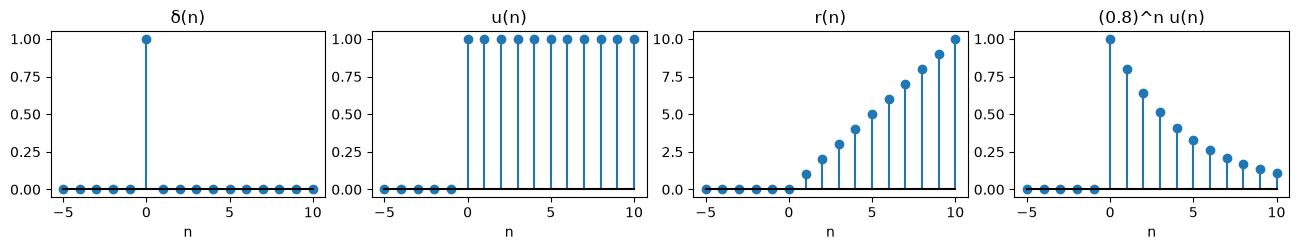

In [3]:
n = np.arange(-5, 11)                 # n = -5, -4, ..., 10
delta = (n == 0).astype(float)        # unit impulse
step  = (n >= 0).astype(float)        # unit step
ramp  = n * step                      # unit ramp
expo  = 0.8**n * step                 # real exponential

fig, axes = plt.subplots(1, 4, figsize=(13, 2.6))
for ax, x, title in zip(axes, [delta, step, ramp, expo],
                        ["δ(n)", "u(n)", "r(n)", "(0.8)^n u(n)"]):
    ax.stem(n, x, basefmt="k-")
    ax.set_title(title); ax.set_xlabel("n")
plt.tight_layout(); plt.show()

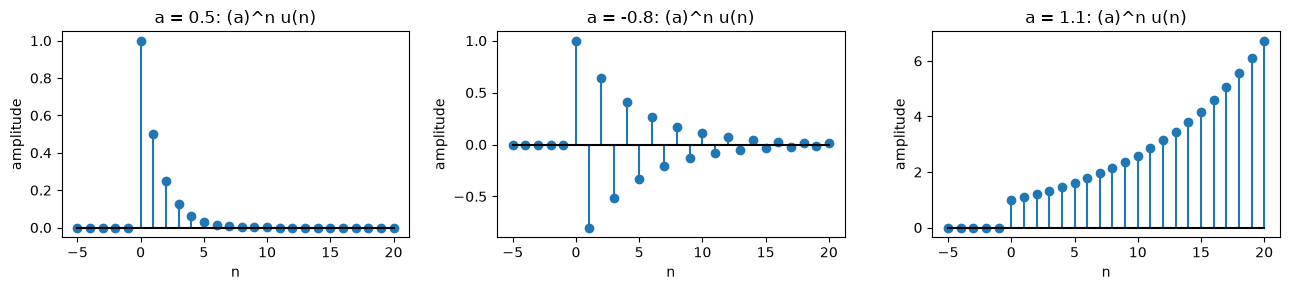

In [4]:
n = np.arange(-5, 21)
step = (n >= 0).astype(float)

fig, axes = plt.subplots(1, 3, figsize=(13, 3))
for ax, a in zip(axes, [0.5, -0.8, 1.1]):
    x = (float(a) ** n) * step
    ax.stem(n, x, basefmt="k-")
    ax.set_title(f"a = {a}: (a)^n u(n)")
    ax.set_xlabel("n"); ax.set_ylabel("amplitude")
plt.tight_layout(); plt.show()

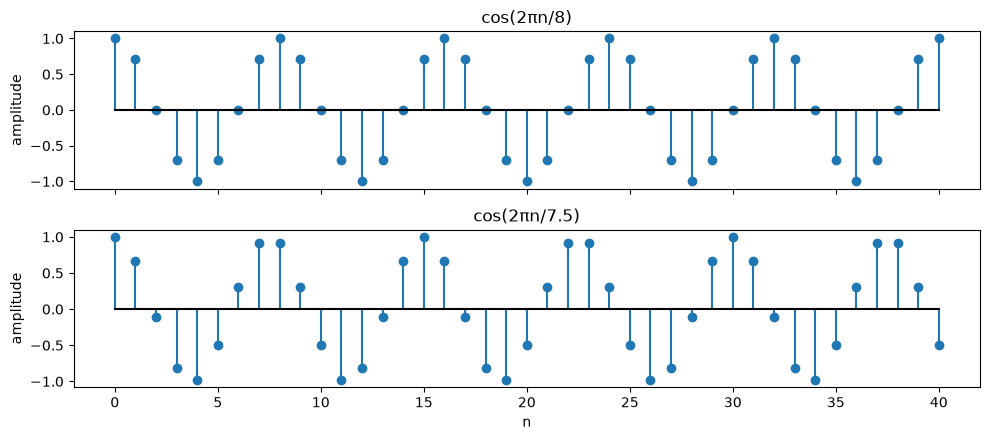

In [5]:
n = np.arange(0, 41)
x1 = np.cos(2*np.pi*n/8)
x2 = np.cos(2*np.pi*n/7.5)

fig, axes = plt.subplots(2, 1, figsize=(10, 4.5), sharex=True)
axes[0].stem(n, x1, basefmt="k-"); axes[0].set_title("cos(2πn/8)")
axes[1].stem(n, x2, basefmt="k-"); axes[1].set_title("cos(2πn/7.5)")
for ax in axes: ax.set_ylabel("amplitude")
axes[1].set_xlabel("n")
plt.tight_layout(); plt.show()

Sampling rate = 48000 Hz
Duration = 6.83 seconds
Total samples = 327680


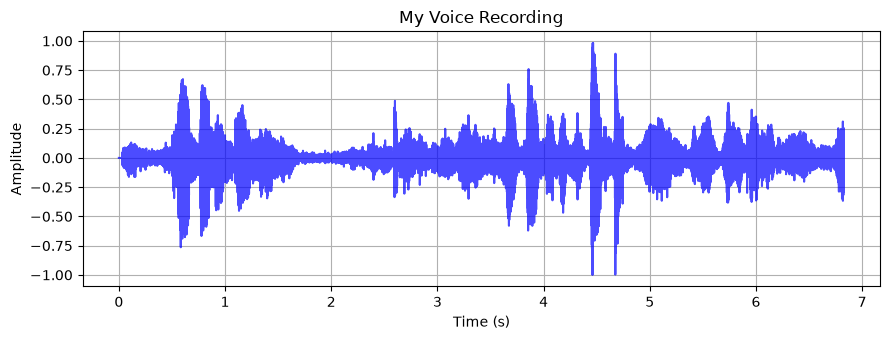

In [2]:
import librosa
import numpy as np
import matplotlib.pyplot as plt
import os
fname = "DSP AUDIO1.wav"          # file sits next to the notebook
if os.path.exists(fname):
    x, fs = librosa.load(fname, sr=None, mono=True)
else:                              # fallback test signal
    fs = 16000
    t = np.arange(0, 2, 1/fs)
    x = 0.5*np.sin(2*np.pi*440*t) * np.exp(-t)


# Normalize audio
peak = np.max(np.abs(x))

if peak > 0:
    x = x / peak

# Time axis
t = np.arange(len(x)) / fs

# Display information
print(f"Sampling rate = {fs} Hz")
print(f"Duration = {len(x) / fs:.2f} seconds")
print(f"Total samples = {len(x)}")

# Plot waveform
plt.figure(figsize=(9, 3.5))
plt.plot(t, x, color="blue", alpha=0.7)
plt.xlabel("Time (s)")
plt.ylabel("Amplitude")
plt.title("My Voice Recording")
plt.grid(True)
plt.tight_layout()
plt.show()